![第三章封面](../../assets/images/chapter-03-cover.jpg)

# 《零基础学习量化金融》
## 从Python到AI量化交易实战 第一期
### 第三章：移动平均线策略

---

## 本章你将学会

- ✅ 区分 **上涨趋势、下跌趋势、噪声**（配图）
- ✅ 理解为什么要用 **移动平均** 看整体走势
- ✅ 计算 **MA5 / MA20**，认出 **金叉 / 死叉**
- ✅ 写出第一个规则：`if MA5 > MA20: 持有`
- ✅ 在图上标 **买点、卖点** 和持仓状态

**当前等级**  
🎮 **Lv.2 策略设计师**

**本章难度**  
⭐⭐☆☆☆

**预计学习时间**  
30～45 分钟（后半段需联网）

**前置知识**

- 完成 **第二章**（收益率、`pct_change`）
- Python 基础、会用 Jupyter

---

从这一章开始，我们真正进入 **「策略」** —— 很多读者最期待的部分：**把看盘直觉写成 if 规则**。

### 环境准备

In [1]:
# ========== 环境准备 ==========
import warnings                          # 导入警告控制模块
warnings.filterwarnings('ignore')  # 隐藏无关警告

import numpy as np              # 数值计算
import pandas as pd             # 表格数据
import matplotlib.pyplot as plt   # 画图
import yfinance as yf # 下载股票行情（需联网）
import akshare as ak                      # 从国内数据源下载 A 股行情

plt.rcParams['font.sans-serif'] = ['SimHei']   # 图表中文
plt.rcParams['axes.unicode_minus'] = False    # 负号正常

TICKER = 'AAPL'   # 股票代码，可改成 TSLA、NVDA
PERIOD = '2y'     # 下载多长历史（均线需要足够天数）

print('环境就绪 ✓')                       # 提示：环境加载完成


环境就绪 ✓


---

### 3.1 什么是趋势？

打开行情软件，最常听到三个词：

| 说法 | 直觉含义 |
|------|----------|
| **上涨趋势** | 价格整体在往上走，低点越来越高 |
| **下跌趋势** | 价格整体在往下走，高点越来越低 |
| **噪声** | 短期上蹿下跳，像「毛刺」，不一定代表大方向变了 |

量化策略的第一步，就是先把 **大方向（趋势）** 和 **每日乱动（噪声）** 分开。

下面用一段 **模拟价格** 把三种状态画在一起（真实股票也是这三种的混合）。

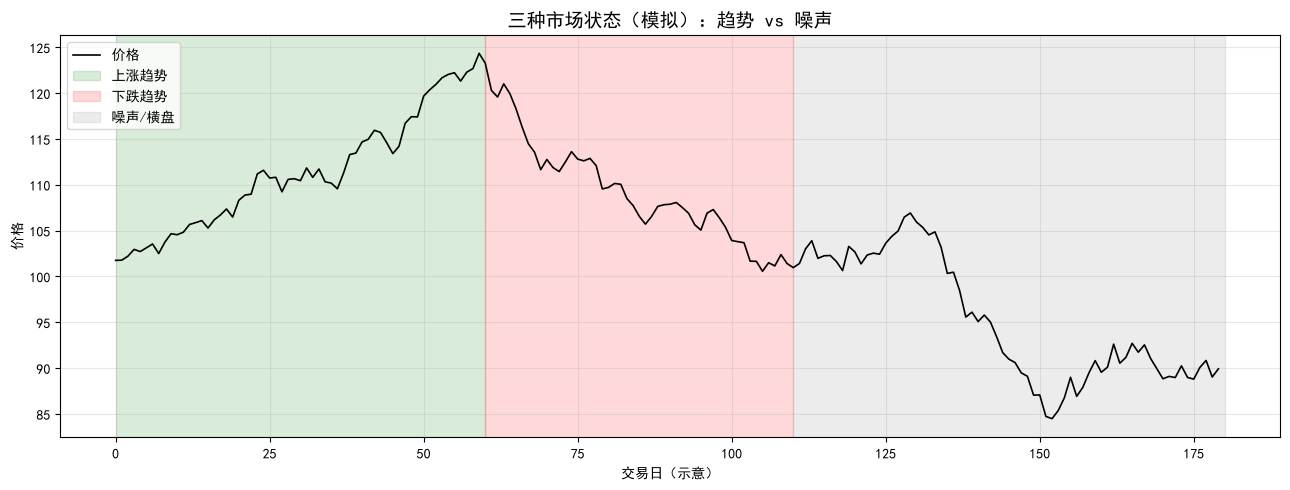

绿色区：整体向上 | 红色区：整体向下 | 灰色区：方向不明显、抖动大


In [2]:
# ========== 模拟三种市场状态并分区上色 ==========
np.random.seed(7)              # 固定随机数，图可复现
n_up, n_down, n_noise = 60, 50, 70  # 上涨段、下跌段、横盘段各多少天

ret_up = np.random.normal(0.004, 0.008, n_up)        # 上涨段：平均日收益偏正
ret_down = np.random.normal(-0.005, 0.010, n_down)   # 下跌段：平均日收益偏负
ret_noise = np.random.normal(0.0, 0.015, n_noise)    # 横盘：均值约0，波动大

price = 100 * np.cumprod(1 + np.r_[ret_up, ret_down, ret_noise])  # 拼成价格
x = np.arange(len(price))  # 横轴：第几个交易日

fig, ax = plt.subplots(figsize=(13, 5))  # 创建子图
ax.plot(x, price, color='black', linewidth=1.2, label='价格')  # 在子图上画折线

ax.axvspan(0, n_up, alpha=0.15, color='green', label='上涨趋势')  # 用色块标出区间
ax.axvspan(n_up, n_up + n_down, alpha=0.15, color='red', label='下跌趋势')  # 用色块标出区间
ax.axvspan(n_up + n_down, len(price), alpha=0.15, color='gray', label='噪声/横盘')  # 用色块标出区间

ax.set_title('三种市场状态（模拟）：趋势 vs 噪声', fontsize=14)  # 设置子图标题
ax.set_xlabel('交易日（示意）')  # 设置子图横轴
ax.set_ylabel('价格')  # 设置子图纵轴
ax.legend(loc='upper left')  # 显示图例
ax.grid(True, alpha=0.3)  # 显示网格
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

print('绿色区：整体向上 | 红色区：整体向下 | 灰色区：方向不明显、抖动大')  # 解读三色区域含义


---

### 3.2 为什么需要「平均」？

真实股票 **每天波动太乱**：一条消息、一笔大单，都可能让当天收盘价上蹿下跳。

但我们做策略时，更关心：

> **「整体趋势」到底在往上还是往下？**

解决办法很朴素：**把最近几天的价格取平均**，就像把毛刺磨平，留下更平滑的「趋势线」。

这就是 **移动平均线（Moving Average, MA）** 的直觉来源。

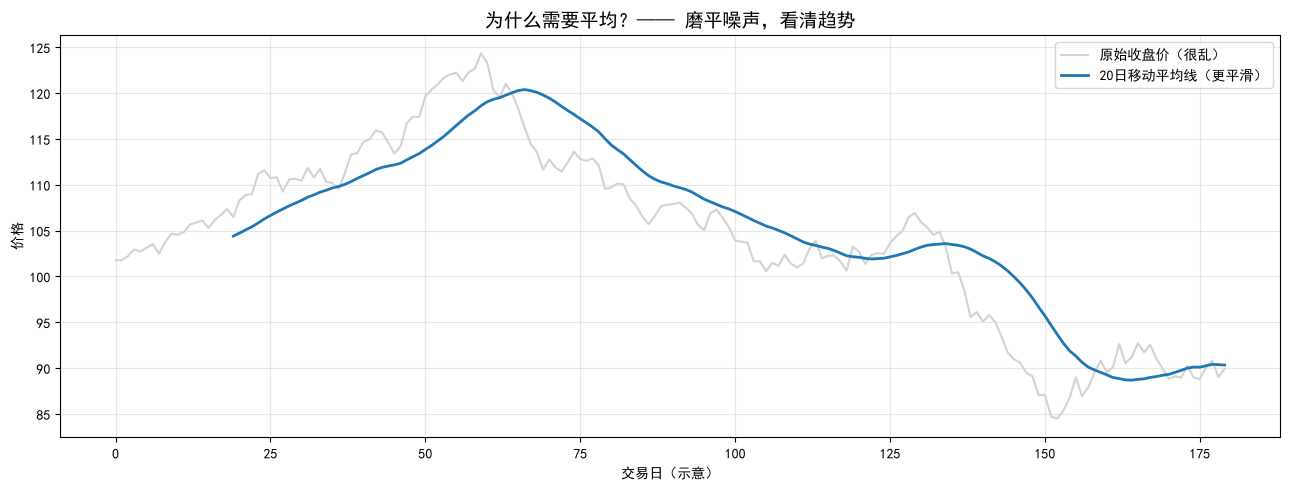

In [3]:
# ========== 对比「乱的价格」和「平滑的均线」==========
demo = pd.DataFrame({'Close': price})           # 用上面模拟的价格
demo['MA20'] = demo['Close'].rolling(20).mean()  # 20日移动平均

fig, ax = plt.subplots(figsize=(13, 5))  # 创建子图
ax.plot(demo['Close'], label='原始收盘价（很乱）', color='lightgray', linewidth=1.5)  # 在子图上画折线
ax.plot(demo['MA20'], label='20日移动平均线（更平滑）', color='tab:blue', linewidth=2)  # 在子图上画折线
ax.set_title('为什么需要平均？—— 磨平噪声，看清趋势', fontsize=14)  # 设置子图标题
ax.set_xlabel('交易日（示意）')  # 设置子图横轴
ax.set_ylabel('价格')  # 设置子图纵轴
ax.legend()                                    # 显示图例
ax.grid(True, alpha=0.3)  # 显示网格
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


---

### 3.3 移动平均线（核心）

**n 日简单移动平均线** 的定义：最近 n 天收盘价的算术平均。

$$
MA_n(t) = \frac{1}{n} \sum_{i=0}^{n-1} P_{t-i}
$$

例如 **MA5** = 最近 5 天收盘价的平均；**MA20** = 最近 20 天收盘价的平均。

- n 越小 → 均线跟价格跟得越紧（更敏感）
- n 越大 → 均线越平滑（更迟钝，但更稳）

在 pandas 里，一行代码：

```python
df['MA5'] = df['Close'].rolling(5).mean()
```

In [4]:
# ========== 【海外用户】用 yfinance 下载并计算 MA5、MA20 ==========
# 大陆网络若连不上 Yahoo，请跳过本格，运行下方 AkShare 那一格
raw = yf.download(TICKER, period=PERIOD, progress=False, multi_level_index=False)  # 下载行情
df = raw[['Close']].dropna().copy()   # 只留收盘价，去掉空行
df.columns = ['Close']                # 列名统一成 Close

df['MA5'] = df['Close'].rolling(5).mean()    # 5日均线 = 最近5天收盘均价
df['MA20'] = df['Close'].rolling(20).mean()  # 20日均线

print(f'{TICKER} 共 {len(df)} 个交易日')  # 打印统计结果
display(df.tail(8))  # 显示最后8行，检查算得对不对



1 Failed download:


['AAPL']: YFRateLimitError('Too Many Requests. Rate limited. Try after a while.')


AAPL 共 0 个交易日


,Close,MA5,MA20


> **大陆学习者**：若上方 `yfinance` 报错或一直转圈，**跳过那一格**，运行下面 AkShare 版本即可。  
> 代码会**自动切换数据源**（腾讯 → 新浪 → 东方财富），避免单一接口 `RemoteDisconnected`。  
> 得到的 `df` 列名相同（`Close` / `MA5` / `MA20`），后面画图、金叉死叉代码**不用改**。

> 本地复现说明：Yahoo Finance 在本机触发限流。本章采用教材已提供的 AkShare 分支，因此实际标的是 A 股 600519（贵州茅台），与 Yahoo 分支的 AAPL 不同；均线和信号计算保持原样。海外用户的 Yahoo 代码单元作为互斥数据路线未执行。

In [5]:
# ========== 【大陆用户】用 AkShare 下载 A 股并计算 MA5、MA20 ==========
from datetime import datetime, timedelta  # 日期计算（起止日）

SYMBOL = '600519'   # A 股 6 位代码：600519 茅台、000001 平安银行、300750 宁德时代
DAYS = 500          # 约 2 年交易日，与上方 PERIOD='2y' 对应

# 6 位代码 → 腾讯/新浪格式（6 开头在上交所用 sh，其余用 sz）
market = 'sh' if SYMBOL.startswith('6') else 'sz'  # 判断上交所 sh 还是深交所 sz
code = f'{market}{SYMBOL}'  # 拼成腾讯/新浪需要的代码格式

end_date = datetime.now().strftime('%Y%m%d')  # 结束日期（今天）
start_date = (datetime.now() - timedelta(days=int(DAYS * 1.6))).strftime('%Y%m%d')  # 多取一些天，再 tail

# 东方财富接口常因限流断开，按稳定性依次尝试
sources = [  # 数据源列表（按稳定性排序）
    ('腾讯证券', lambda: ak.stock_zh_a_hist_tx(symbol=code, start_date=start_date, end_date=end_date, adjust='qfq')),  # 腾讯证券前复权日线
    ('新浪财经', lambda: ak.stock_zh_a_daily(symbol=code, start_date=start_date, end_date=end_date, adjust='qfq')),  # 新浪财经前复权日线
    ('东方财富', lambda: ak.stock_zh_a_hist(symbol=SYMBOL, period='daily', start_date=start_date, end_date=end_date, adjust='qfq')),  # 东方财富前复权日线
]                                              # 数组拼接结束
raw, last_err = None, None              # 初始化：原始数据、最后一次报错
for name, fetch in sources:  # 依次尝试各个数据源
    try:  # 尝试当前数据源
        raw = fetch()  # 下载原始行情
        print(f'数据来源：{name}')  # 格式化打印
        break                        # 成功拿到数据，跳出循环
    except Exception as e:  # 当前源失败则换下一个
        last_err = e  # 赋值：last_err
        print(f'{name} 暂不可用，尝试下一个…')  # 格式化打印
if raw is None:                               # 三个数据源都失败
    raise last_err  # 抛出错误

# 统一成 Close 列（不同接口列名略有差异）
raw = raw.copy()                              # 复制一份，避免改到原始表
if '收盘' in raw.columns:  # 东方财富接口的列名
    raw['日期'] = pd.to_datetime(raw['日期'])  # 转成日期时间格式
    df = raw.set_index('日期')[['收盘']].rename(columns={'收盘': 'Close'})  # 把某列设为行索引（日期）
elif 'close' in raw.columns:  # 腾讯/新浪接口的列名
    raw['date'] = pd.to_datetime(raw['date'])  # 转成日期时间格式
    df = raw.set_index('date')[['close']].rename(columns={'close': 'Close'})  # 把某列设为行索引（日期）
else:                              # 否则：本轮亏损
    raise ValueError('未识别的行情格式，请检查 akshare 版本')  # 抛出错误

df = pd.to_numeric(df['Close'], errors='coerce').to_frame().sort_index().dropna().tail(DAYS).copy()  # 删除空值行
df['MA5'] = df['Close'].rolling(5).mean()  # 滚动窗口计算
df['MA20'] = df['Close'].rolling(20).mean()  # 滚动窗口计算

TICKER = SYMBOL     # 后面图表标题会用到这个变量
print(f'{SYMBOL} 共 {len(df)} 个交易日')  # 打印统计结果
display(df.tail(8))  # 在 Notebook 中美观显示表格

  0%|          | 0/2 [00:00<?, ?it/s]

数据来源：腾讯证券
600519 共 500 个交易日


,Close,MA5,MA20
date,,,
2026-10-28,1330.75,1338.024,1294.6315
2026-10-29,1354.00,1345.126,1299.7695
2026-10-30,1392.05,1356.536,1307.5220
2026-11-02,1439.10,1374.360,1317.2830
2026-11-03,1480.00,1399.180,1329.5040
2026-11-04,1446.44,1422.318,1338.8950
2026-11-05,1452.00,1441.918,1348.7055
2026-11-06,1453.00,1454.108,1358.2055


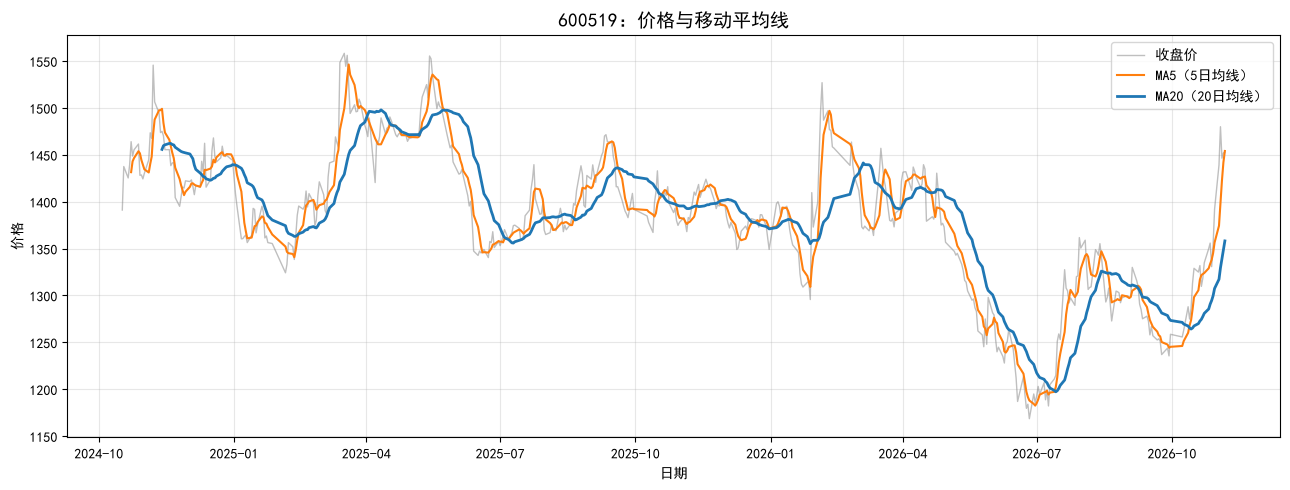

In [6]:
# ========== 画收盘价 + 两条均线 ==========
plt.figure(figsize=(13, 5))  # 创建画布
plt.plot(df.index, df['Close'], label='收盘价', color='gray', alpha=0.5, linewidth=1)  # 画折线图
plt.plot(df.index, df['MA5'], label='MA5（5日均线）', color='tab:orange', linewidth=1.5)  # 画折线图
plt.plot(df.index, df['MA20'], label='MA20（20日均线）', color='tab:blue', linewidth=2)  # 画折线图
plt.title(f'{TICKER}：价格与移动平均线', fontsize=14)  # 设置图标题
plt.xlabel('日期')  # 设置横轴标签
plt.ylabel('价格')  # 设置纵轴标签
plt.legend()  # 显示图例
plt.grid(True, alpha=0.3)  # 显示网格线
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


---

### 3.4 5日均线 vs 20日均线（本章高潮）

当 **短期均线** 和 **长期均线** 放在一起，会出现两种经典形态：

| 名称 | 发生了什么 | 市场直觉 |
|------|------------|----------|
| **金叉** | MA5 **从下往上** 穿过 MA20 | 短期变强，常被看作 **偏多 / 买入信号** |
| **死叉** | MA5 **从上往下** 穿过 MA20 | 短期变弱，常被看作 **偏空 / 卖出信号** |

> 注意：金叉/死叉是 **描述交叉现象** 的用语，不等于「一定赚钱」——后面章节会做回测验证。

下面在图上标出每一个金叉、死叉的位置。

In [7]:
# ========== 检测金叉、死叉 ==========
df['spread'] = df['MA5'] - df['MA20']              # 短均线减长均线
df['cross'] = np.sign(df['spread']).diff()         # 符号变化：正=金叉，负=死叉

golden = df[df['cross'] > 0].dropna(subset=['MA5', 'MA20'])  # 金叉那些天
death = df[df['cross'] < 0].dropna(subset=['MA5', 'MA20'])    # 死叉那些天

print(f'样本期内 金叉 {len(golden)} 次，死叉 {len(death)} 次')  # 打印统计结果
print('\n最近 3 次金叉日期：')  # 打印输出
print(golden.tail(3).index.strftime('%Y-%m-%d').tolist())  # 打印输出
print('\n最近 3 次死叉日期：')  # 打印输出
print(death.tail(3).index.strftime('%Y-%m-%d').tolist())  # 打印输出


样本期内 金叉 15 次，死叉 15 次

最近 3 次金叉日期：
['2026-07-14', '2026-09-08', '2026-10-13']

最近 3 次死叉日期：
['2026-04-21', '2026-08-19', '2026-09-11']


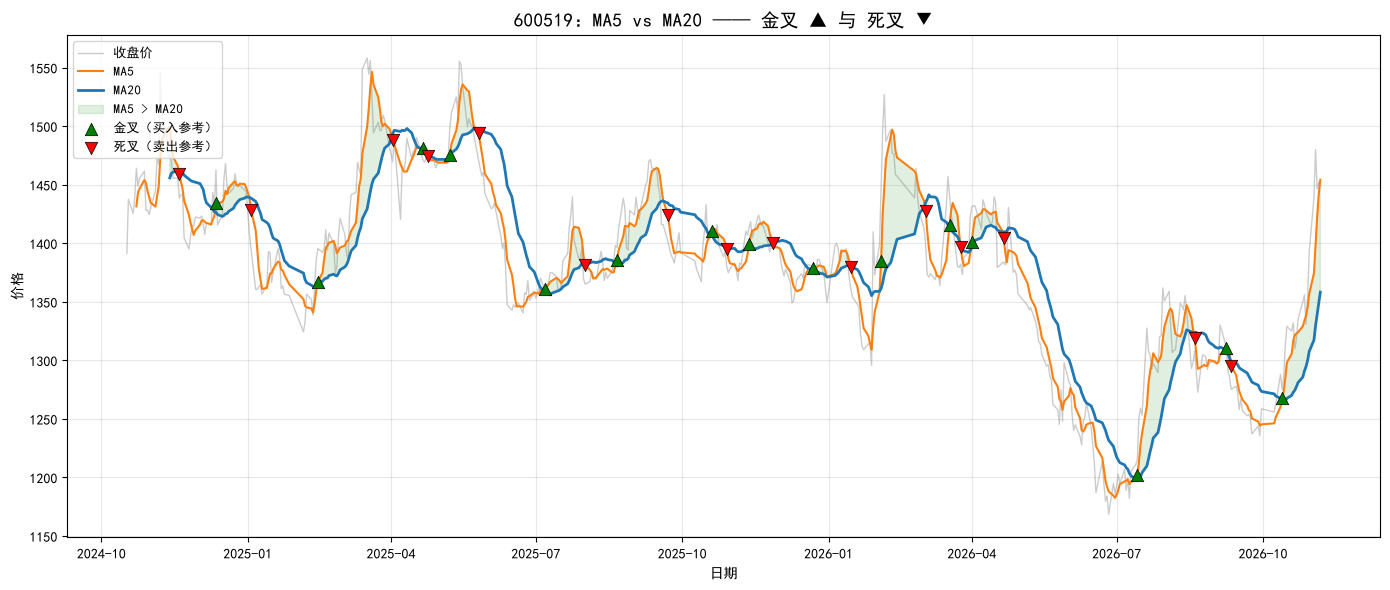

In [8]:
# ========== 金叉死叉标注图 ==========
fig, ax = plt.subplots(figsize=(14, 6))  # 创建子图

ax.plot(df.index, df['Close'], color='gray', alpha=0.4, linewidth=1, label='收盘价')  # 在子图上画折线
ax.plot(df.index, df['MA5'], color='tab:orange', linewidth=1.5, label='MA5')  # 在子图上画折线
ax.plot(df.index, df['MA20'], color='tab:blue', linewidth=2, label='MA20')  # 在子图上画折线

ax.fill_between(df.index, df['MA5'], df['MA20'],  # 在子图上填充区域
                where=(df['MA5'] >= df['MA20']),  # 计算 5 日移动平均线
                interpolate=True, alpha=0.12, color='green', label='MA5 > MA20')  # 填充区域平滑过渡

ax.scatter(golden.index, golden['MA5'], marker='^', s=80, color='green',  # 在子图上画散点
           edgecolors='black', linewidths=0.5, zorder=5, label='金叉（买入参考）')  # 图层顺序（点在线上方）
ax.scatter(death.index, death['MA5'], marker='v', s=80, color='red',  # 在子图上画散点
           edgecolors='black', linewidths=0.5, zorder=5, label='死叉（卖出参考）')  # 图层顺序（点在线上方）

ax.set_title(f'{TICKER}：MA5 vs MA20 —— 金叉 ▲ 与 死叉 ▼', fontsize=14)  # 设置子图标题
ax.set_xlabel('日期')  # 设置子图横轴
ax.set_ylabel('价格')  # 设置子图纵轴
ax.legend(loc='upper left', fontsize=9)  # 显示图例
ax.grid(True, alpha=0.3)  # 显示网格
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


---

### 3.5 你的第一个策略

把上面的直觉写成 **可执行的规则**（伪代码）：

```text
如果 MA5 > MA20:
    持有 / 买入
否则:
    空仓 / 卖出
```

这就是著名的 **双均线策略（Moving Average Crossover）** 的最简版本。

在 pandas 里，`signal = 1` 表示持仓，`0` 表示空仓：

In [9]:
# ========== 第一个策略：MA5>MA20 则持仓 ==========
df['signal'] = (df['MA5'] > df['MA20']).astype(int)  # 满足条件=1，否则=0

df['trade'] = 0                              # 默认无交易
df.loc[df['cross'] > 0, 'trade'] = 1         # 金叉日标记买入
df.loc[df['cross'] < 0, 'trade'] = -1        # 死叉日标记卖出

hold_days = df['signal'].sum()             # signal=1 的天数
print(f'规则：MA5 > MA20 则持仓 (signal=1)')  # 格式化打印
print(f'样本期内约 {hold_days} 个交易日处于持仓状态（共 {len(df)} 天）')  # 打印统计结果
print(f'共产生 { (df["trade"] != 0).sum() } 次调仓信号（买+卖）')  # 格式化打印

display(df[df['trade'] != 0][['Close', 'MA5', 'MA20', 'signal', 'trade']].tail(6))  # 在 Notebook 中美观显示表格


规则：MA5 > MA20 则持仓 (signal=1)
样本期内约 222 个交易日处于持仓状态（共 500 天）
共产生 30 次调仓信号（买+卖）


,Close,MA5,MA20,signal,trade
date,,,,,
2026-04-21,1383.99,1404.076,1409.6950,0,-1
2026-07-14,1214.88,1202.468,1197.2880,1,1
2026-08-19,1307.88,1319.248,1323.9220,0,-1
2026-09-08,1309.30,1310.338,1307.7750,1,1
2026-09-11,1275.16,1295.296,1298.3195,0,-1
2026-10-13,1274.89,1268.060,1265.3825,1,1


**恭喜你** —— 你已经把「看盘感觉」写成了 **if 判断 + 表格列**，这就是量化策略的起点。

真实交易还要考虑手续费、滑点、能否当天成交等；**第四章回测** 会帮你用数据检验「这套规则到底赚没赚」。

小提示：为避免 **未来函数**，回测时常用 `signal.shift(1)`——今天收盘算出的信号，明天才能按它交易。本章先聚焦「规则与可视化」。

---

### 3.6 可视化策略信号（非常重要）

一张好的策略图应让人 **一眼看懂**：

- 价格 + 两条均线
- **绿色 ▲** = 买入点（金叉）
- **红色 ▼** = 卖出点（死叉）
- 下方色带 = 当前是持仓还是空仓

这类图会让你的 Notebook 立刻有「专业量化报告」的味道。

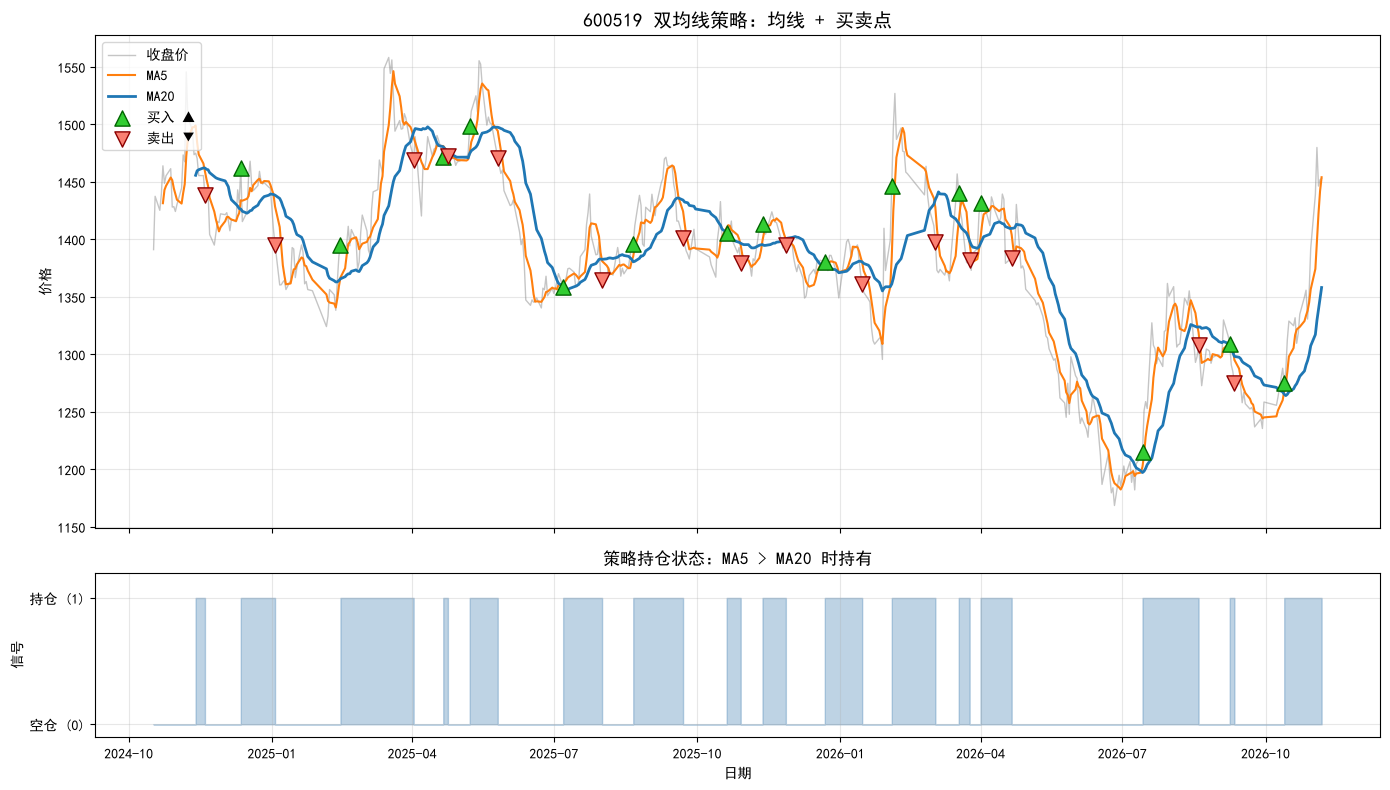

In [10]:
# ========== 策略信号大图：价格+买卖点+持仓条 ==========
buys = df[df['trade'] == 1]    # 所有买入日
sells = df[df['trade'] == -1]  # 所有卖出日

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,  # 创建子图
                         gridspec_kw={'height_ratios': [3, 1]})  # 子图高度比例
ax_price, ax_pos = axes  # 上图价格、下图持仓

ax_price.plot(df.index, df['Close'], color='gray', alpha=0.45, linewidth=1, label='收盘价')  # 透明度
ax_price.plot(df.index, df['MA5'], color='tab:orange', linewidth=1.5, label='MA5')  # 计算 5 日移动平均线
ax_price.plot(df.index, df['MA20'], color='tab:blue', linewidth=2, label='MA20')  # 计算 20 日移动平均线

ax_price.scatter(buys.index, buys['Close'], marker='^', s=120, color='limegreen',  # 上三角标记（买入/金叉）
                 edgecolors='darkgreen', linewidths=1, zorder=6, label='买入 ▲')  # 散点边框颜色
ax_price.scatter(sells.index, sells['Close'], marker='v', s=120, color='salmon',  # 下三角标记（卖出/死叉）
                 edgecolors='darkred', linewidths=1, zorder=6, label='卖出 ▼')  # 散点边框颜色

ax_price.set_title(f'{TICKER} 双均线策略：均线 + 买卖点', fontsize=14)  # 上图标题
ax_price.set_ylabel('价格')                                          # 上图纵轴：价格
ax_price.legend(loc='upper left')                                    # 显示图例
ax_price.grid(True, alpha=0.3)                                       # 显示网格

ax_pos.fill_between(df.index, 0, df['signal'], step='post', alpha=0.35, color='steelblue')  # 策略信号：1=持仓，0=空仓
ax_pos.set_ylim(-0.1, 1.2)  # 执行本行代码
ax_pos.set_yticks([0, 1])  # 执行本行代码
ax_pos.set_yticklabels(['空仓 (0)', '持仓 (1)'])  # 执行本行代码
ax_pos.set_xlabel('日期')  # 执行本行代码
ax_pos.set_ylabel('信号')  # 执行本行代码
ax_pos.set_title('策略持仓状态：MA5 > MA20 时持有', fontsize=12)  # 字号
ax_pos.grid(True, alpha=0.3)  # 透明度

plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


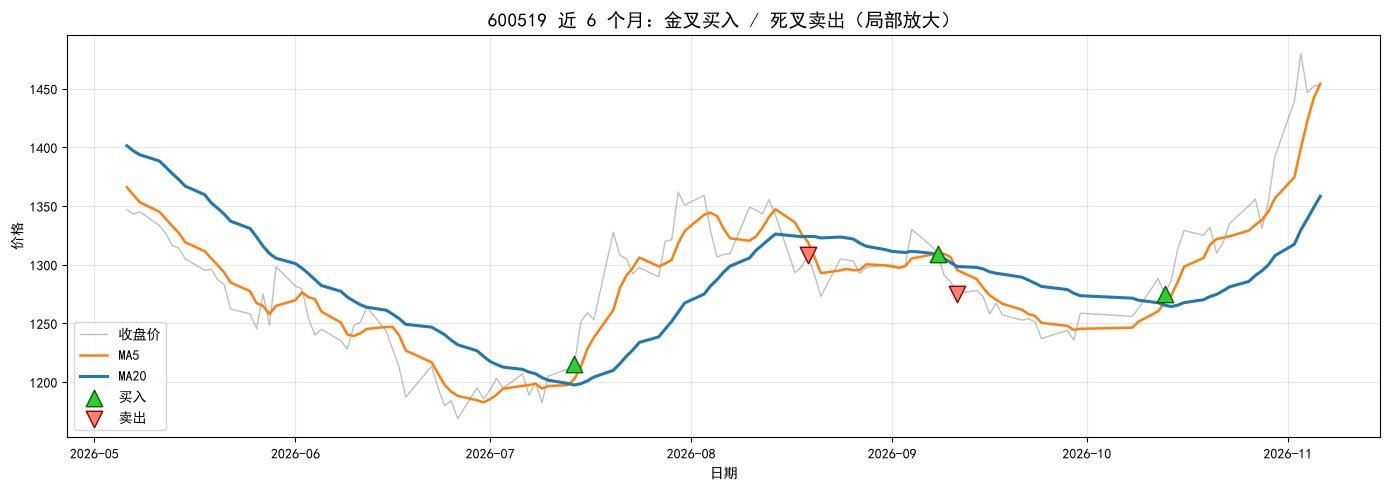

In [11]:
# ========== 放大最近6个月，看清买卖细节 ==========
# pandas 3.x 移除了 DataFrame.last；按日期掩码取近六个月
recent = df.loc[df.index >= df.index.max() - pd.DateOffset(months=6)] if len(df) > 120 else df.tail(120)  # 取最近约6个月
buys_r = recent[recent['trade'] == 1]  # 最近区间的买入点
sells_r = recent[recent['trade'] == -1]  # 最近区间的卖出点

fig, ax = plt.subplots(figsize=(14, 5))  # 创建子图
ax.plot(recent.index, recent['Close'], color='gray', alpha=0.5, linewidth=1, label='收盘价')  # 在子图上画折线
ax.plot(recent.index, recent['MA5'], color='tab:orange', linewidth=1.8, label='MA5')  # 在子图上画折线
ax.plot(recent.index, recent['MA20'], color='tab:blue', linewidth=2.2, label='MA20')  # 在子图上画折线
ax.scatter(buys_r.index, buys_r['Close'], marker='^', s=140, color='limegreen',  # 在子图上画散点
           edgecolors='darkgreen', linewidths=1, zorder=6, label='买入')  # 散点边框颜色
ax.scatter(sells_r.index, sells_r['Close'], marker='v', s=140, color='salmon',  # 在子图上画散点
           edgecolors='darkred', linewidths=1, zorder=6, label='卖出')  # 散点边框颜色
ax.set_title(f'{TICKER} 近 6 个月：金叉买入 / 死叉卖出（局部放大）', fontsize=14)  # 设置子图标题
ax.set_xlabel('日期')  # 设置子图横轴
ax.set_ylabel('价格')  # 设置子图纵轴
ax.legend()                                    # 显示图例
ax.grid(True, alpha=0.3)  # 显示网格
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


---

## 🎯 挑战任务（第三章通关）

1. 把 `TICKER` 改成 **`'TSLA'`**，截一张带 **金叉▲ / 死叉▼** 的图——这就是你的第一张「策略信号图」。  
2. 试试 **MA10 vs MA30**，和 MA5/MA20 比：买卖次数变多了还是变少了？  
3. **思考题**：金叉一定赚钱吗？为什么第四章要做回测？

---

## 本章总结

- **趋势** 是大方向；**噪声** 是短期乱动；均线用来「磨平」噪声。  
- $MA_n$ = 最近 n 天收盘价的平均；`rolling(n).mean()` 即可计算。  
- **金叉**（MA5 上穿 MA20）≈ 买入参考；**死叉** ≈ 卖出参考。  
- 你的第一个策略：`signal = (MA5 > MA20)` —— 你已经写出 **交易系统** 了。  
- 策略图 = 均线 + 买卖点 + 持仓色带，专业感来自 **可视化**。

**下一章预告**：第四章 **策略回测** —— 用历史数据回答：这套双均线规则，到底赚没赚钱？最大回撤有多大？

### 本地挑战复现

本单元完成本章挑战：TSLA，比较 MA5/20。价格数据只使用项目真实行情 CSV 缓存。

MA5/20: 金叉 14 次，死叉 14 次
MA10/30: 金叉 9 次，死叉 9 次


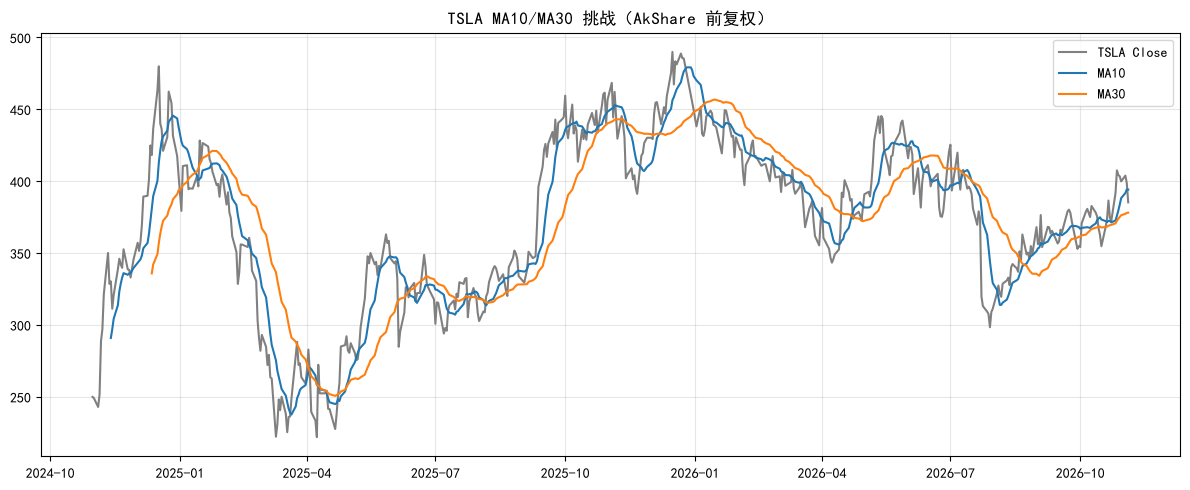

思考：金叉不保证盈利，因为信号可能滞后、横盘时反复，且未计手续费/滑点；回测用于检查历史表现及风险，但不保证未来。


In [12]:
# 第三章挑战：TSLA，比较 MA5/20 与 MA10/30 信号
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
px = pd.read_csv('../../data/akshare_us/TSLA.csv', parse_dates=['date']).set_index('date')['close'].dropna().tail(504)
challenge = pd.DataFrame({'Close':px})
for short,long in [(5,20),(10,30)]:
 challenge[f'MA{short}']=challenge.Close.rolling(short).mean(); challenge[f'MA{long}']=challenge.Close.rolling(long).mean()
 spread=challenge[f'MA{short}']-challenge[f'MA{long}']; cross=np.sign(spread).diff()
 print(f'MA{short}/{long}: 金叉 {(cross>0).sum()} 次，死叉 {(cross<0).sum()} 次')
challenge['signal']=(challenge.MA10>challenge.MA30).astype(int)
fig,ax=plt.subplots(figsize=(12,5));ax.plot(challenge.index,challenge.Close,label='TSLA Close',color='gray');ax.plot(challenge.index,challenge.MA10,label='MA10');ax.plot(challenge.index,challenge.MA30,label='MA30');ax.legend();ax.grid(alpha=.3);ax.set_title('TSLA MA10/MA30 挑战（AkShare 前复权）');plt.tight_layout();plt.show()
print('思考：金叉不保证盈利，因为信号可能滞后、横盘时反复，且未计手续费/滑点；回测用于检查历史表现及风险，但不保证未来。')

### 挑战完成记录
使用 TSLA 近约 504 个交易日，比较 MA5/20 与 MA10/30 的交叉次数，并绘制 MA10/30。较长窗口通常更平滑且反应更慢，具体交叉次数以本次实际输出为准。金叉是规则信号而非盈利保证；第四章回测用于把信号转成滞后仓位后评估历史收益与回撤。

In [13]:
# ========== 环境准备 ==========
import warnings                          # 导入警告控制模块
warnings.filterwarnings('ignore')  # 隐藏无关警告

import numpy as np              # 数值计算
import pandas as pd             # 表格数据
import matplotlib.pyplot as plt   # 画图
import yfinance as yf # 下载股票行情（需联网）
import akshare as ak                      # 从国内数据源下载 A 股行情

plt.rcParams['font.sans-serif'] = ['SimHei']   # 图表中文
plt.rcParams['axes.unicode_minus'] = False    # 负号正常

TICKER = 'TSLA'   # 股票代码，可改成 TSLA、NVDA
PERIOD = '2y'     # 下载多长历史（均线需要足够天数）

print('环境就绪 ✓')                       # 提示：环境加载完成

环境就绪 ✓


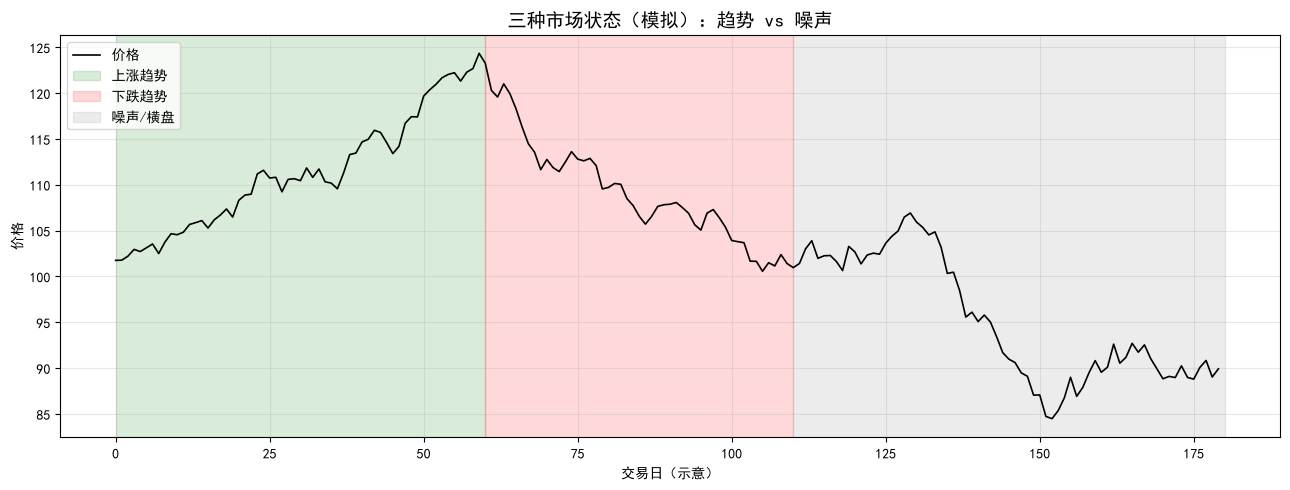

绿色区：整体向上 | 红色区：整体向下 | 灰色区：方向不明显、抖动大


In [14]:
# ========== 模拟三种市场状态并分区上色 ==========
np.random.seed(7)              # 固定随机数，图可复现
n_up, n_down, n_noise = 60, 50, 70  # 上涨段、下跌段、横盘段各多少天

ret_up = np.random.normal(0.004, 0.008, n_up)        # 上涨段：平均日收益偏正
ret_down = np.random.normal(-0.005, 0.010, n_down)   # 下跌段：平均日收益偏负
ret_noise = np.random.normal(0.0, 0.015, n_noise)    # 横盘：均值约0，波动大

price = 100 * np.cumprod(1 + np.r_[ret_up, ret_down, ret_noise])  # 拼成价格
x = np.arange(len(price))  # 横轴：第几个交易日

fig, ax = plt.subplots(figsize=(13, 5))  # 创建子图
ax.plot(x, price, color='black', linewidth=1.2, label='价格')  # 在子图上画折线

ax.axvspan(0, n_up, alpha=0.15, color='green', label='上涨趋势')  # 用色块标出区间
ax.axvspan(n_up, n_up + n_down, alpha=0.15, color='red', label='下跌趋势')  # 用色块标出区间
ax.axvspan(n_up + n_down, len(price), alpha=0.15, color='gray', label='噪声/横盘')  # 用色块标出区间

ax.set_title('三种市场状态（模拟）：趋势 vs 噪声', fontsize=14)  # 设置子图标题
ax.set_xlabel('交易日（示意）')  # 设置子图横轴
ax.set_ylabel('价格')  # 设置子图纵轴
ax.legend(loc='upper left')  # 显示图例
ax.grid(True, alpha=0.3)  # 显示网格
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

print('绿色区：整体向上 | 红色区：整体向下 | 灰色区：方向不明显、抖动大')  # 解读三色区域含义
